In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt

In [2]:
from alexgpt.tokenizer import CharTokenizer

with open("../data/TinyStories-valid.txt", "r", encoding="utf-8") as f:
    text = f.read()

tok = CharTokenizer(text)
ids = np.array(tok.encode(text), dtype=np.int64)
print(len(ids), tok.vocab_size)

19432979 98


In [3]:
from alexgpt.tensor import Tensor, matmul, add_bias, tanh, embed, cross_entropy

vocab_size = tok.vocab_size
context_size = 8

split = int(0.9 * len(ids))
train_ids = ids[:split]
val_ids = ids[split:]

rng = np.random.default_rng(42)

def get_batch(data_ids, batch_size):
    # random start positions in the text
    starts = rng.integers(0, len(data_ids) - context_size, size=batch_size)
    contexts = np.zeros((batch_size, context_size), dtype=np.int64)
    for position in range(context_size):
        contexts[:, position] = data_ids[starts + position]
    targets = data_ids[starts + context_size]     # the char right after the context
    return contexts, targets

contexts, targets = get_batch(train_ids, 4)
for i in range(4):
    print(repr(tok.decode(contexts[i])), "->", repr(tok.decode([targets[i]])))

'very gra' -> 'c'
'd the ve' -> 's'
'ntinued ' -> 't'
' and pla' -> 'y'


In [4]:
embed_dim = 16
hidden_size = 200

table = Tensor(rng.normal(0, 1, size=(vocab_size, embed_dim)))
W1 = Tensor(rng.normal(0, 1, size=(context_size * embed_dim, hidden_size)) / np.sqrt(context_size * embed_dim))
b1 = Tensor(np.zeros(hidden_size))
W2 = Tensor(rng.normal(0, 1, size=(hidden_size, vocab_size)) * 0.01)
b2 = Tensor(np.zeros(vocab_size))
params = [table, W1, b1, W2, b2]

def forward(contexts):
    x = embed(table, contexts)                    # (batch, 128)
    hidden = tanh(add_bias(matmul(x, W1), b1))    # (batch, 200)
    logits = add_bias(matmul(hidden, W2), b2)     # (batch, vocab_size)
    return logits

num_params = 0
for param in params:
    num_params += param.data.size
print("parameters:", num_params)

parameters: 47066


0 4.582220560915757 0.0 s
5000 1.4906736916846004 3.3 s
10000 1.8229049927692653 6.4 s
15000 1.3857925764165162 9.6 s
20000 1.3632640112544316 12.7 s
25000 0.9745924347816474 15.9 s


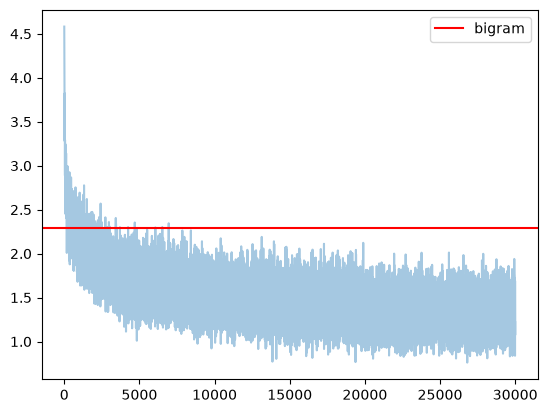

In [5]:
import time

loss_history = []
num_steps = 30000
batch_size = 64
start_time = time.time()

for step in range(num_steps):
    contexts, targets = get_batch(train_ids, batch_size)
    loss = cross_entropy(forward(contexts), targets)

    for param in params:
        param.grad = np.zeros(param.data.shape)
    loss.backward()

    if step < 20000:
        learning_rate = 0.1
    else:
        learning_rate = 0.01      # smaller steps at the end, to settle in the valley
    for param in params:
        param.data -= learning_rate * param.grad

    loss_history.append(float(loss.data))
    if step % 5000 == 0:
        print(step, float(loss.data), round(time.time() - start_time, 1), "s")

plt.plot(loss_history, alpha=0.4)
plt.axhline(2.296, color="red", label="bigram")
plt.legend()
plt.show()

In [6]:
contexts, targets = get_batch(val_ids, 20000)
val_loss = cross_entropy(forward(contexts), targets)
print("validation loss:", float(val_loss.data), "  (bigram: 2.296)")

validation loss: 1.359716556459624   (bigram: 2.296)


In [7]:
def generate(prompt, num_chars, temperature=1.0):
    generated = tok.encode(prompt)
    for _ in range(num_chars):
        context = np.array([generated[-context_size:]])    # last 8 chars, as a batch of 1
        logits = forward(context).data[0] / temperature
        logits = logits - logits.max()
        probs = np.exp(logits) / np.exp(logits).sum()
        next_id = rng.choice(vocab_size, p=probs)
        generated.append(int(next_id))
    return tok.decode(generated)

print(generate("Once upo", 400))
print("-----")
print(generate("Once upo", 400, temperature=0.6))

Once upon Camer handed porral zo play’t wron the flower do playing to that frogine. every day to deet in the roon a turned the day dading bow theirs good its doochad. Lily was very neard his mound. He would yod can't day oftok a felt, you nees. They helpughe Mpob. He three dround. He was very was time nois!
"Don't working mind a sure use tiding, patestibus saw a gree begants Ary a felt lot't haped was Ary
-----
Once upon a time, better and started.
"I thole. He was the toy. The moray of the tree with his house. They had said, "I'm sorry. He saw a big the gave help her got to some found and went to the man went back ful day to started to seed him to the said. "Her the park. He loved to clean the pare the bird so happy. She had a big back something good!" 
The can for the belims no fuch fun to the other and starte


f:\Code\PersonalProjects\LLM\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127891 (\N{GRADUATION CAP}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


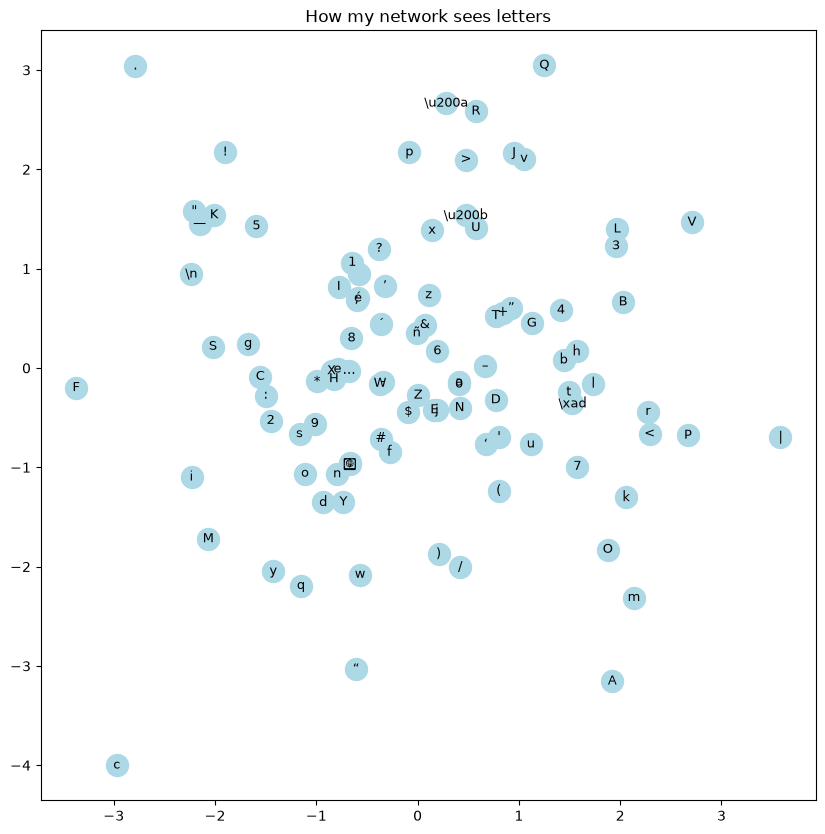

In [8]:
# best 2D "photo" of the 16-dimensional letter space (PCA)
vectors = table.data - table.data.mean(axis=0)     # center the cloud of points
u, s, directions = np.linalg.svd(vectors)            # find the 2 directions with most spread
points_2d = vectors @ directions[:2].T               # project every letter onto them

plt.figure(figsize=(10, 10))
plt.scatter(points_2d[:, 0], points_2d[:, 1], s=250, color="lightblue")
for i in range(vocab_size):
    plt.text(points_2d[i, 0], points_2d[i, 1], repr(tok.itos[i])[1:-1],
             ha="center", va="center", fontsize=9)
plt.title("How my network sees letters")
plt.show()

In [9]:
np.savez("../checkpoints/slate.npz",
         table=table.data, W1=W1.data, b1=b1.data, W2=W2.data, b2=b2.data,
         chars=np.array(tok.chars), context_size=context_size)